Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


LSTM Model Performance
----------------------
Mean Squared Error: 1230943171.18
Root Mean Squared Error: 35084.8


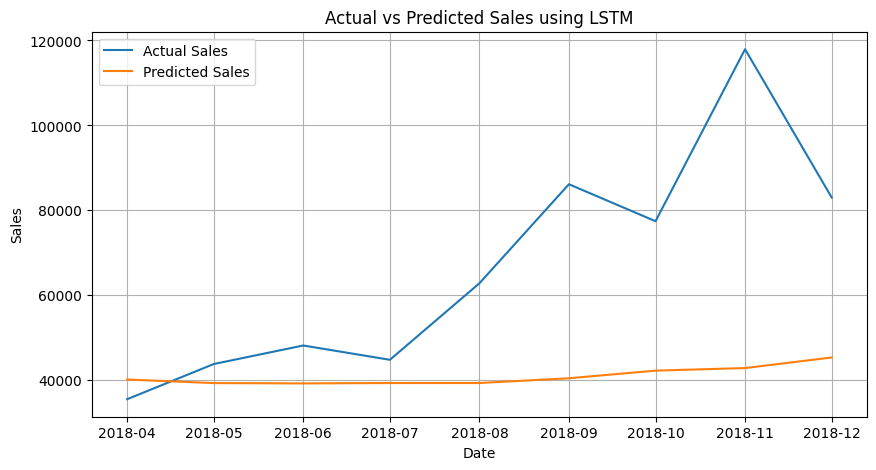


Future Sales Forecast
---------------------
January 2019 : 44818.02
February 2019 : 42487.42
March 2019 : 41032.04
April 2019 : 40086.22
May 2019 : 39531.1
June 2019 : 39046.2


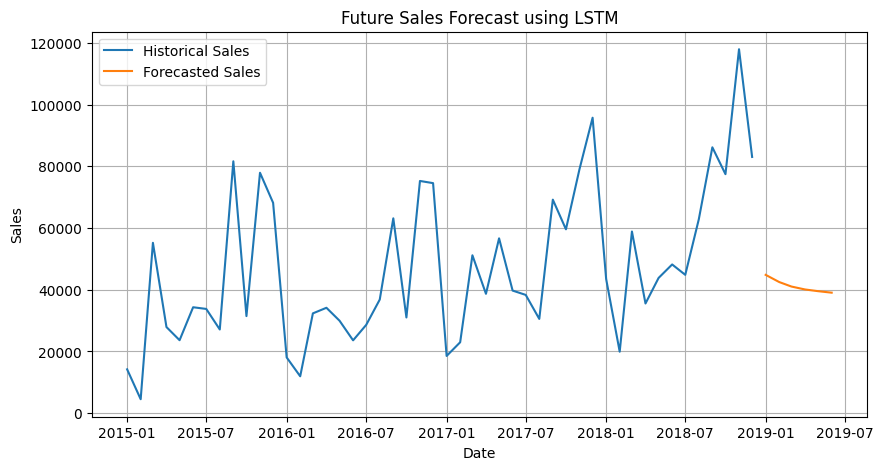

In [4]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/PBA PRACTICAL FILE/superstore.csv')

# Convert date
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)

# Monthly sales
monthly_sales = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum()
monthly_sales.index = monthly_sales.index.to_timestamp()

# Scale data
sales = monthly_sales.values.reshape(-1, 1)
scaler = MinMaxScaler()
scaled_sales = scaler.fit_transform(sales)

# Create sequences
time_steps = 6
X, y = [], []

for i in range(time_steps, len(scaled_sales)):
    X.append(scaled_sales[i-time_steps:i])
    y.append(scaled_sales[i])

X = np.array(X)
y = np.array(y)

# Train-test split
train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test = X[train_size:]
y_train = y[:train_size]
y_test = y[train_size:]

# Build LSTM model
model = Sequential([
    LSTM(50, input_shape=(time_steps, 1)),
    Dense(1)])
model.compile(optimizer='adam', loss='mean_squared_error')

# Train model
model.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)

# Predict
predicted = model.predict(X_test, verbose=0)
predicted_sales = scaler.inverse_transform(predicted)
actual_sales = scaler.inverse_transform(y_test)

# Evaluation
mse = mean_squared_error(actual_sales, predicted_sales)
rmse = np.sqrt(mse)

print("LSTM Model Performance")
print("----------------------")
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))

# Actual vs predicted
test_dates = monthly_sales.index[time_steps + train_size:]

plt.figure(figsize=(10, 5))
plt.plot(test_dates, actual_sales, label='Actual Sales')
plt.plot(test_dates, predicted_sales, label='Predicted Sales')
plt.title('Actual vs Predicted Sales using LSTM')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid()
plt.show()

# Forecast next 6 months
last_sequence = scaled_sales[-time_steps:]
future_predictions = []
for i in range(6):
    input_data = last_sequence.reshape(1, time_steps, 1)
    next_value = model.predict(input_data, verbose=0)[0][0]
    future_predictions.append(next_value)
    last_sequence = np.append(last_sequence[1:], next_value)

future_predictions = scaler.inverse_transform(
    np.array(future_predictions).reshape(-1, 1)).flatten()

future_dates = pd.date_range(
    start=monthly_sales.index[-1] + pd.DateOffset(months=1),
    periods=6,
    freq='MS')

print("\nFuture Sales Forecast")
print("---------------------")
for date, value in zip(future_dates, future_predictions):
    print(date.strftime('%B %Y'), ":", round(value, 2))

# Forecast graph
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values, label='Historical Sales')
plt.plot(future_dates, future_predictions, label='Forecasted Sales')
plt.title('Future Sales Forecast using LSTM')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid()
plt.show()